# AINT604 Week 7 — Activity 1: Measuring fairness on the COMPAS data

**Time:** 45–60 minutes. **Environment:** Google Colab.

COMPAS is a criminal justice risk assessment tool. In this activity you will compare two fairness concerns: whether prediction errors are distributed similarly across groups, and whether the same score corresponds to similar observed outcomes in those groups. You will then explore how changing a classification threshold affects other measures and recommend appropriate governance controls.

**Data.** `compas-scores-two-years.csv`, released by ProPublica (2016) in its analysis of Broward County, Florida. Each row describes a person assessed using COMPAS. `decile_score` is an ordinal risk score from 1 to 10, **not a probability**, while `two_year_recid` indicates *recorded two-year recidivism*, an outcome derived from criminal justice records.

**Group labels.** For this teaching exercise, the two largest demographic categories in the filtered data will appear as **Group A** and **Group B** (ordered by frequency after filtering). These are display aliases, not anonymisation; the original data retain the underlying demographic information. Neutral labels help focus on metrics, but they cannot substitute for understanding real-world group context in an actual fairness audit.

**Ethical note.** These are records about real people. Recorded recidivism is not the same as all actual offending: arrests and official records can reflect differences in policing and observation. Interpret findings accordingly.

**Learning objectives**
1. Compute and interpret selection rates, true-positive rates, false-positive rates and positive predictive values by group.
2. Compare an error-rate fairness argument with an argument about score calibration across groups.
3. Change a decision threshold and observe its effects on other measures of fairness.
4. Write a short recommendation to the decision owner.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
raw = pd.read_csv(URL)
print("Dataset dimensions:", raw.shape)
# Show example columns without displaying the original demographic labels.
raw[["age", "decile_score", "score_text", "two_year_recid"]].head()

Dataset dimensions: (7214, 53)


,age,decile_score,score_text,two_year_recid
0,69,1,Low,0
1,34,3,Low,1
2,24,4,Low,1
3,23,8,High,0
4,43,1,Low,0


## 1. Apply ProPublica's filters

Apply the screening-window, outcome-availability and charge filters used in the published analysis. Keep only the two largest demographic categories so that the comparison is manageable. The code maps them to **Group A** and **Group B**.

In [3]:
df = raw[(raw.days_b_screening_arrest <= 30) & (raw.days_b_screening_arrest >= -30)
         & (raw.is_recid != -1) & (raw.c_charge_degree != "O") & (raw.score_text != "N/A")].copy()

# Choose the two largest categories after filtering, without showing category names.
top_two = df["race"].value_counts().head(2).index.to_list()
assert len(top_two) == 2, "Expected at least two demographic categories."
group_map = {top_two[0]: "Group A", top_two[1]: "Group B"}
df = df[df["race"].isin(top_two)].copy()
df["group"] = df["race"].map(group_map)
# The original category names are not needed in subsequent student-facing analyses.
df = df.drop(columns=["race"])

df["high_risk"] = (df.decile_score >= 5).astype(int)  # 'Medium' or 'High'
df["y"] = df.two_year_recid  # 1 = recorded two-year recidivism
print("Filtered dataset dimensions:", df.shape)
df.groupby("group")[["y", "high_risk"]].mean().round(3).rename(
    columns={"y": "recorded event rate", "high_risk": "high-risk label rate"}
)

Filtered dataset dimensions: (5278, 55)


,recorded event rate,high-risk label rate
group,,
Group A,0.523,0.576
Group B,0.391,0.331


**Question 1.** Compare the recorded two-year recidivism rates in Group A and Group B. Why might different underlying event rates make it difficult to satisfy several fairness metrics simultaneously?

## 2. Group fairness metrics

Compute each metric from observed labels (`y`) and binary high-risk labels (`high_risk`). **Equal opportunity** compares true-positive rates (TPRs); **equalised odds** compares both TPRs and false-positive rates (FPRs). **Predictive parity** compares positive predictive values (PPVs). PPV is *not* the same as calibration of the original 1–10 risk score, which is examined separately below.

In [4]:
def metrics(g):
    y, yhat = g["y"].to_numpy(), g["high_risk"].to_numpy()
    tp = ((y == 1) & (yhat == 1)).sum()
    fp = ((y == 0) & (yhat == 1)).sum()
    fn = ((y == 1) & (yhat == 0)).sum()
    tn = ((y == 0) & (yhat == 0)).sum()
    return pd.Series({
        "n": len(g),
        "Positive rate [demographic parity]": yhat.mean(),
        "TPR P(high | recorded event) [equal opportunity]": tp / (tp + fn),
        "FPR P(high | no recorded event) [equalised odds]": fp / (fp + tn),
        "FNR P(low | recorded event)": fn / (fn + tp),
        "PPV P(recorded event | high) [predictive parity]": tp / (tp + fp),
        "Accuracy": (tp + tn) / len(g),
    })

# Rows are metrics; columns show only neutral group labels.
table = pd.concat({name: metrics(g) for name, g in df.groupby("group")}, axis=1).round(3)
table

,Group A,Group B
n,3175.000,2103.000
Positive rate [demographic parity],0.576,0.331
TPR P(high | recorded event) [equal opportunity],0.715,0.504
FPR P(high | no recorded event) [equalised odds],0.423,0.220
FNR P(low | recorded event),0.285,0.496
PPV P(recorded event | high) [predictive parity],0.650,0.595
Accuracy,0.649,0.672


**Question 2.** Which results indicate differences in **false-positive rates** between Group A and Group B? How do their **false-negative rates** compare? Does PPV appear similar across the groups? Explain what each comparison means for individuals receiving risk labels.

*Published figures may not match yours exactly if analysts use different filters or cohort definitions. Focus on the pattern and state which data you used.*

**Question 3.** Which group fairness criteria are approximately satisfied, and which are not? Use the positive rate, TPR, FPR and PPV rows to justify your answer. Why is PPV not sufficient to establish that the full risk score is calibrated?

## 3. Compare observed event rates at the same score

One defence of COMPAS concerned **between-group score calibration**: people assigned a particular score had roughly similar observed recorded two-year recidivism rates across groups. Explore that claim below.

**Important:** The COMPAS decile score (1–10) is a ranked risk category, not a probability. A score of 7 does **not** mean a 70% predicted probability. This graph compares *observed event rates at each score* between groups; it does not by itself establish absolute probabilistic calibration.

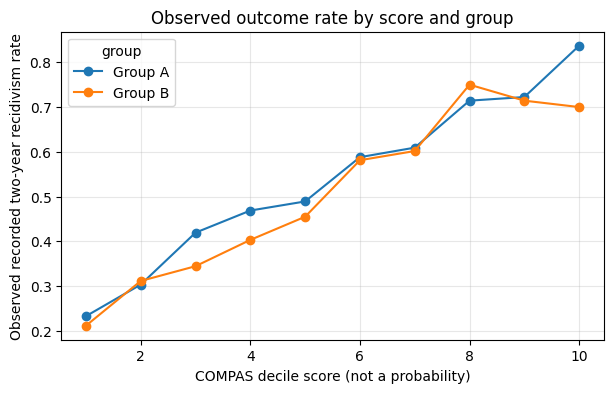

group,Group A,Group B
decile_score,,
1,0.23,0.21
2,0.30,0.31
3,0.42,0.34
4,0.47,0.40
5,0.49,0.46
6,0.59,0.58
7,0.61,0.60
8,0.71,0.75
9,0.72,0.71


In [5]:
cal = df.groupby(["group", "decile_score"])["y"].mean().unstack(0)
ax = cal.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("COMPAS decile score (not a probability)")
ax.set_ylabel("Observed recorded two-year recidivism rate")
ax.set_title("Observed outcome rate by score and group")
ax.grid(alpha=0.3)
plt.show()
cal.round(2)

**Question 4.** At the same COMPAS score, are observed recorded two-year recidivism rates reasonably similar across Group A and Group B? Compare this pattern with the FPR results in Section 2. How might the score have similar meanings across groups yet produce unequal binary classification errors? Answer in two or three sentences.

## 4. Try to reduce an FPR gap: group-specific thresholds

Suppose the decision owner asks whether the false-positive rates can be made more similar. One possible, but ethically and legally sensitive, approach is to change the threshold for one group. Keep **Group B at threshold 5** and search for the threshold for **Group A** whose FPR is closest to Group B's.

Compare the resulting TPR, PPV and positive rate with the original values. **Changing a binary threshold can change PPV (predictive parity), but it does not change the calibration of the underlying decile scores.** This is an illustration for analysis, not a recommendation to deploy group-specific thresholds.

In [6]:
def fpr_at(g, t):
    yhat = (g.decile_score >= t).astype(int)
    y = g.y
    return ((y == 0) & (yhat == 1)).sum() / (y == 0).sum()

group_a = df[df.group == "Group A"]
group_b = df[df.group == "Group B"]
target = fpr_at(group_b, 5)
rows = []
for t in range(1, 11):
    yhat = (group_a.decile_score >= t).astype(int)
    y = group_a.y
    tp = ((y == 1) & (yhat == 1)).sum()
    fp = ((y == 0) & (yhat == 1)).sum()
    fn = ((y == 1) & (yhat == 0)).sum()
    rows.append({
        "threshold": t,
        "FPR": fpr_at(group_a, t),
        "TPR": tp / (tp + fn),
        "PPV": tp / max(tp + fp, 1),
        "positive rate": yhat.mean(),
    })
res = pd.DataFrame(rows).set_index("threshold").round(3)
best = (res.FPR - target).abs().idxmin()
print(f"Group B FPR at threshold 5: {target:.3f}")
print(f"Group A threshold giving the closest FPR: {best}")
res.style.apply(lambda r: ["background-color: #EBD4F7" if r.name == best else "" for _ in r], axis=1)

Group B FPR at threshold 5: 0.220
Group A threshold giving the closest FPR: 7


,FPR,TPR,PPV,positive rate
threshold,,,,
1,1.000000,1.000000,0.523000,1.000000
2,0.815000,0.949000,0.561000,0.885000
3,0.656000,0.886000,0.597000,0.776000
4,0.542000,0.810000,0.621000,0.682000
5,0.423000,0.715000,0.650000,0.576000
6,0.314000,0.620000,0.684000,0.474000
7,0.228000,0.508000,0.710000,0.374000
8,0.139000,0.382000,0.750000,0.266000
9,0.083000,0.252000,0.770000,0.171000


**Question 5.** Compare Group A's TPR and PPV at the selected threshold with its values at threshold 5, and with Group B's values at threshold 5. What trade-offs do you observe? If a court used these scores as **one input** to release or detention decisions, how could changes in false-positive and false-negative rates affect the people concerned? Do **not** assume that a high-risk label automatically leads to detention.

**Question 6.** Different thresholds for demographic groups involve explicit differential treatment. What legal and ethical questions would need to be resolved before considering this approach? Who should be accountable for choosing a fairness criterion: the developer, vendor, court, or an appropriate public authority? Explain your reasoning.

## 5. Uncertainty check (optional, 10 minutes)

Risk scores may appear more precise than the available evidence supports. Use bootstrap resampling to see how estimated recorded two-year recidivism rates vary for deciles 5 and 6. Should a decision-maker automatically regard those two scores as meaningfully different? Why or why not?

In [7]:
rng = np.random.default_rng(0)
sub = df[df.decile_score.isin([5, 6])]
boot = {d: [] for d in (5, 6)}
for _ in range(500):
    s = sub.sample(len(sub), replace=True, random_state=int(rng.integers(1e9)))
    for d in (5, 6):
        boot[d].append(s[s.decile_score == d].y.mean())
for d in (5, 6):
    lo, hi = np.percentile(boot[d], [2.5, 97.5])
    print(f"Decile {d}: observed event rate {sub[sub.decile_score == d].y.mean():.3f}, "
          f"bootstrap 95% interval [{lo:.3f}, {hi:.3f}]")

Decile 5: observed event rate 0.476, bootstrap 95% interval [0.432, 0.514]
Decile 6: observed event rate 0.586, bootstrap 95% interval [0.536, 0.629]


## 6. Advice to the decision owner (submit this)

In **150–200 words**, write to the Chief Judge (the decision owner) and address:

1. Which fairness criterion should the court prioritise when using pre-trial risk scores, and why? Identify the potential errors and who might bear their consequences.
2. One technical control, one governance control and one public-accountability control, each with a named owner.
3. One action you would advise the court **not** to take.

Post your paragraph to the discussion board and respond to one peer who prioritised a different fairness criterion.

---
